# Tidal Flooding
## FloodNet NYC Tutorial
Author: Mark Bauer

# Summary

Notebooks [05](https://github.com/mebauer/floodnet-nyc-tutorial/blob/main/05-temporal-patterns.ipynb) and [06](https://github.com/mebauer/floodnet-nyc-tutorial/blob/main/06-rain-episodes.ipynb) follow rain-driven flooding and set tidal sensors aside. This notebook does the opposite: it looks only at sensors flagged `tidally_influenced`, where streets flood when high tides push water up through storm drains or over the shoreline.

These datasets contain no tide record, so everything here is inferred from **when** the sensors flooded. If tides drive the flooding, it should show up in the timing: floods roughly 12.4 hours apart, more floods around new and full moon, and seasonal changes. The patterns we find are consistent with tides, not proof of them.

1. **Which Sensors Are Tidal?**: counts, a map, and how the tidal network grew
2. **One Event, Several Tides**: a worked example of one event spanning two high tides
3. **Tides in the Timing**: the gaps between successive events at each sensor
4. **Spring and Neap Tides**: flooding through the lunar cycle
5. **Seasonality**: tidal floods per active sensor-month by calendar month
6. **Limitations**

### A few terms, in plain words

- **Event**: a run of depth readings above 10 mm (about 0.4 in) at one sensor, verified by FloodNet. One row in the Flood Events dataset.
- **Flood**: an event that peaks at **4 inches or more** at the sensor. Each count below says whether it uses events or floods.
- **Tidal cycle**: the main lunar tide (M2) brings a high tide about every **12.42 hours**, so high tides arrive about 50 minutes later each day.
- **Spring and neap tides**: around new and full moon the sun and moon pull together and the tidal range is largest (spring tides, nothing to do with the season). About a week later the range is smallest (neap tides). The cycle repeats every half lunar month, about 14.8 days.
- **Per sensor**: every result here is per `sensor_id`. A replaced sensor gets a new id, so one street location can appear as more than one sensor (see [METHODS.md](METHODS.md), caveat 9).

# Import Libraries

In [1]:
# libraries
# Standard library
from datetime import datetime, timezone

# Third-party
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import floodnet

# series colors, matching 05-temporal-patterns.ipynb and 07-rise-and-peak-depth.ipynb
colors = floodnet.COLORBLIND_PALETTE
TIDAL_COLOR = colors[4]      # cyan
NON_TIDAL_COLOR = colors[0]  # blue

FLOOD_IN = 4         # flood tier: peak >= 4 in at the sensor (METHODS.md)
M2_HOURS = 12.42     # period of the main lunar tide

# 1) Which Sensors Are Tidal?

We load the two datasets, join them on `sensor_id`, add New York local-time (`_et`) copies of the UTC timestamps, and decode the depth profiles, as in the earlier notebooks.

In [2]:
# read the two datasets and join them on sensor_id
metadata_df = pl.read_csv("data/sensor-metadata.csv", try_parse_dates=True)
events_df = pl.read_csv(
    "data/flood-events.csv",
    infer_schema_length=100000,  # sparse columns need a deep scan to type correctly
    try_parse_dates=True,
)
merged_df = events_df.join(
    metadata_df.drop("sensor_name"),
    on="sensor_id",
    how="left",  # keep all events, even if metadata is missing
)

# timestamps are UTC; add New York local-time (_et) copies, which handle daylight saving
merged_df = floodnet.to_local_time(merged_df)

# the per-event depth/time profiles arrive as JSON strings; decode to list columns
merged_df = merged_df.with_columns(
    pl.col("flood_profile_time_secs").str.json_decode(pl.List(pl.Float64)),
    pl.col("flood_profile_depth_inches").str.json_decode(pl.List(pl.Float64)),
)

tidal_df = merged_df.filter(pl.col("tidally_influenced") == "Yes")
tidal_floods_df = tidal_df.filter(pl.col("max_depth_inches") >= FLOOD_IN)

# data cutoff: end of the latest event, not the download date (METHODS.md)
data_cutoff = merged_df["flood_end_time_et"].max().date()
print(f"Data cutoff: {data_cutoff} (ET)")

Data cutoff: 2026-11-09 (ET)


Start with the size of each group: how many sensors, how long they've been deployed, and how many events and floods they recorded. **Sensor-years** add up each sensor's time from installation to removal or the data cutoff (`floodnet.days_deployed`). They assume every sensor worked the whole time, so they are an upper bound on the time actually observed (caveat 6).

In [3]:
deployed_df = floodnet.days_deployed(metadata_df, data_cutoff)

group_summary = (
    metadata_df.select("sensor_id", "tidally_influenced")
    .join(deployed_df, on="sensor_id")
    .join(
        merged_df.group_by("sensor_id").agg(
            pl.len().alias("events"),
            (pl.col("max_depth_inches") >= FLOOD_IN).sum().alias("floods"),
        ),
        on="sensor_id",
        how="left",
    )
    .group_by("tidally_influenced")
    .agg(
        pl.len().alias("sensors"),
        pl.col("events").is_not_null().sum().alias("sensors_with_events"),
        (pl.col("days_deployed").clip(lower_bound=0).sum() / 365.25).round(1).alias("sensor_years"),
        pl.col("events").sum().alias("events"),
        pl.col("floods").sum().alias("floods"),
    )
    .with_columns(
        (pl.col("floods") / pl.col("sensor_years")).round(1).alias("floods_per_sensor_year")
    )
    .sort("tidally_influenced", descending=True)
)
group_summary

tidally_influenced,sensors,sensors_with_events,sensor_years,events,floods,floods_per_sensor_year
str,u32,u32,f64,u32,u32,f64
"""Yes""",67,56,142.1,2440,1241,8.7
"""No""",429,266,719.2,1171,361,0.5


Compare the `sensors` column with the `events` and `floods` columns. A smaller group of sensors can still record more flooding, because a tidal site can flood with many high tides a year. That's why notebooks [02](https://github.com/mebauer/floodnet-nyc-tutorial/blob/main/02-sensor-rankings.ipynb), [05](https://github.com/mebauer/floodnet-nyc-tutorial/blob/main/05-temporal-patterns.ipynb) and [07](https://github.com/mebauer/floodnet-nyc-tutorial/blob/main/07-rise-and-peak-depth.ipynb) split the two groups: in a pooled result, whichever group floods more dominates.

## Where Are They?

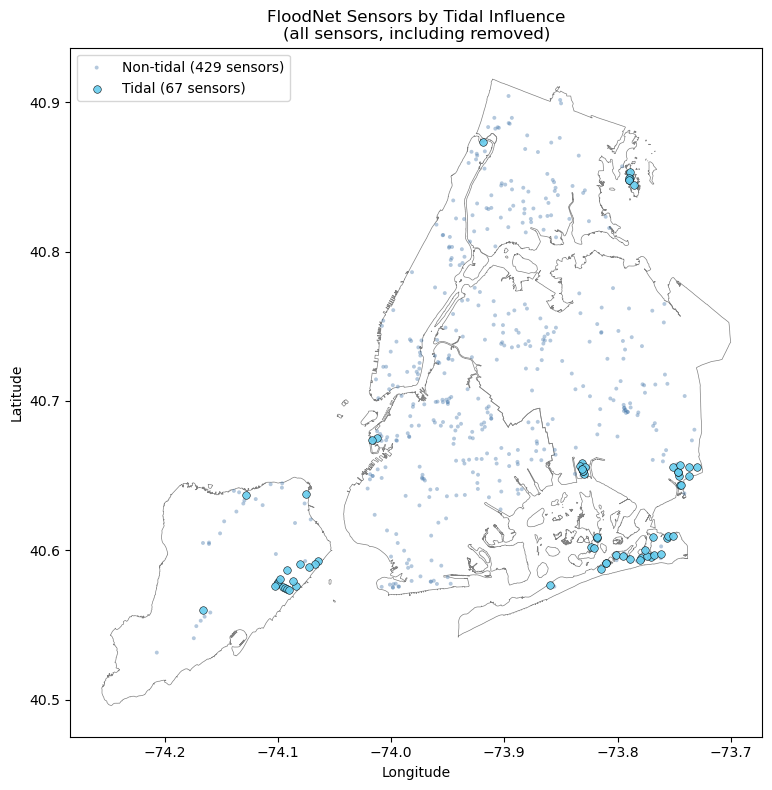

In [4]:
boro_gdf = gpd.read_parquet("data/boroughs.parquet").to_crs(epsg=4326)

fig, ax = plt.subplots(figsize=(8, 8))
boro_gdf.plot(ax=ax, facecolor="none", edgecolor="gray", linewidth=0.5, zorder=0)
for flag, color, label, size in [
    ("No", NON_TIDAL_COLOR, "Non-tidal", 8),
    ("Yes", TIDAL_COLOR, "Tidal", 30),
]:
    sub = metadata_df.filter(pl.col("tidally_influenced") == flag)
    ax.scatter(sub["longitude"], sub["latitude"], s=size, color=color,
               edgecolor="black" if flag == "Yes" else "none", linewidth=0.4,
               alpha=0.9 if flag == "Yes" else 0.4,
               label=f"{label} ({sub.height} sensors)")
ax.set_title("FloodNet Sensors by Tidal Influence\n(all sensors, including removed)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Tidal sensors sit along the coast and tidal creeks, where low-lying streets connect to tidal water. FloodNet chooses sites that are known to flood (caveat 5), so the map shows where tidal flooding is **watched**, not every place it happens.

## How the Tidal Network Grew

The network was built over several years (caveat 7). Before comparing time periods, check how many tidal sensors were installed each year.

In [5]:
installs_by_year = (
    metadata_df
    .with_columns(pl.col("date_installed").dt.year().alias("year_installed"))
    .group_by("year_installed")
    .agg(
        (pl.col("tidally_influenced") == "Yes").sum().alias("tidal"),
        (pl.col("tidally_influenced") == "No").sum().alias("non_tidal"),
    )
    .sort("year_installed")
    .with_columns(pl.col("tidal").cum_sum().alias("tidal_installed_to_date"))
)
installs_by_year

year_installed,tidal,non_tidal,tidal_installed_to_date
i32,u32,u32,u32
2020,0,2,0
2021,5,7,5
2022,1,19,6
2023,27,33,33
2024,12,151,45
2025,5,101,50
2026,17,116,67


Look at the early years in the `tidal` column. If only a few tidal sensors were installed then, any rate for those years rests on those few sites. Sections 4 and 5 pool the whole record, so they mostly describe the years when the tidal network was largest.

## A Few Sensors Record Most Tidal Floods

The table below lists the tidal sensors with the most floods and each one's share of all tidal floods. It's a **raw count**, so it also reflects how long each sensor has been deployed (`days_deployed` is shown for that reason). It is not a ranking of where flooding is worst (caveat 5). We look at it to see how much a pooled tidal result depends on a handful of sensors.

In [6]:
TOP_N = 10  # display choice

top_tidal = (
    tidal_floods_df.group_by("sensor_id", "sensor_name")
    .agg(pl.len().alias("floods"))
    .join(deployed_df, on="sensor_id")
    .with_columns((pl.col("floods") / tidal_floods_df.height * 100).round(1).alias("pct_of_tidal_floods"))
    .sort(["floods", "sensor_id"], descending=[True, False])
    .with_columns(pl.col("pct_of_tidal_floods").cum_sum().round(1).alias("cumulative_pct"))
)

top2_pct = top_tidal["pct_of_tidal_floods"].head(2).sum()
print(f"Tidal floods (peak >= {FLOOD_IN} in): {tidal_floods_df.height:,}, "
      f"at {top_tidal.height} sensors")
print(f"Share from the top 2 sensors: {top2_pct:.1f}%")
top_tidal.head(TOP_N).select(
    "sensor_name", "floods", "pct_of_tidal_floods", "cumulative_pct", "days_deployed"
)

Tidal floods (peak >= 4 in): 1,241, at 46 sensors
Share from the top 2 sensors: 41.2%


sensor_name,floods,pct_of_tidal_floods,cumulative_pct,days_deployed
str,u32,f64,f64,i64
"""Q - Beach 84 St""",274,22.1,22.1,1795
"""BX - Ditmars St/Hunter Ave 2""",237,19.1,41.2,1124
"""Q - Russell St 1""",99,8.0,49.2,2075
"""Q - Beach 84 St (2)""",83,6.7,55.9,376
"""Q - Brookville Blvd/ Snake Rd …",67,5.4,61.3,760
"""Q - Davenport Ct 1""",53,4.3,65.6,2075
"""Q - Beach 35 St/Beach Channel …",41,3.3,68.9,1056
"""Q - Russell St 2""",40,3.2,72.1,1077
"""Q - 102nd St/160th Ave""",38,3.1,75.2,1113


Read the `cumulative_pct` column. If the first two or three rows already account for a large share, then any pooled tidal chart in this notebook mostly describes those sites. Where it matters, the later sections also show the result per sensor, or without the top two sensors.

## Replaced Sensors Can Change Flag

When a sensor is replaced, the new one gets a new `sensor_id`, and its metadata can differ from the original's (caveat 9). The cell below finds sites (same `sensor_name`) whose sensors disagree on `tidally_influenced`. Replacement sensors sometimes get a suffix such as "2" or "(2)" in their name, so this check can miss some replaced sensors. Treat it as a check, not a complete list.

In [7]:
mixed_flag_sites = (
    metadata_df.group_by("sensor_name")
    .agg(pl.col("tidally_influenced").n_unique().alias("flags"))
    .filter(pl.col("flags") > 1)["sensor_name"]
)
print(f"Sites whose sensors disagree on tidal influence: {mixed_flag_sites.len()}")
metadata_df.filter(pl.col("sensor_name").is_in(mixed_flag_sites.implode())).select(
    "sensor_name", "sensor_id", "tidally_influenced", "date_installed", "date_removed"
).sort("sensor_name", "date_installed")

Sites whose sensors disagree on tidal influence: 1


sensor_name,sensor_id,tidally_influenced,date_installed,date_removed
str,str,str,datetime[μs],datetime[μs]
"""BK - Van Brunt St/Reed St""","""BK-van-brunt-st-reed-st-0pzyg0""","""No""",2022-02-18 00:00:00,2022-12-27 00:00:00
"""BK - Van Brunt St/Reed St""","""BK-van-brunt-st-reed-st-2zaf4o""","""Yes""",2026-06-17 00:00:00,null


If a site appears here, its events are split between the tidal and non-tidal groups depending on which sensor recorded them. Keep that in mind if it is one of the busier sites.

# 2) One Event, Several Tides

An event lasts as long as the water stays above 10 mm, give or take short dips. At a tidal sensor, water can stay in the street between two high tides, so one event can span **more than one tide**. That event counts once, and its `duration_mins` includes the low-tide trough in between (caveat 3).

To find these events, we look inside each tidal flood's depth profile for **separate rises above 4 inches**. A rise is a run of readings at or above 4 inches, and its **peak** is its deepest reading. Two rises whose peaks are less than **half a tidal cycle (6.2 hours)** apart are joined into one: high tides come about 12.4 hours apart, so two peaks a few minutes or hours apart are the depth flickering around 4 inches or one tide's uneven crest, not two tides.

In [8]:
def separate_rises(secs, depths, depth_in=FLOOD_IN, min_gap_h=M2_HOURS / 2):
    """Peak times (hours from event start) of the separate rises above `depth_in`.

    A rise is a run of readings at or above `depth_in`; its peak is its
    deepest reading. Rises whose peaks are less than `min_gap_h` hours apart
    are joined, keeping the deeper peak. A gap in the readings doesn't end
    a rise; only a reading below `depth_in` does.
    """
    rises = []  # [peak_depth, peak_time_s] per rise
    in_rise = False
    for t, d in zip(secs, depths):
        if d < depth_in:
            in_rise = False
            continue
        if not in_rise:
            rises.append([d, t])
            in_rise = True
        elif d > rises[-1][0]:
            rises[-1] = [d, t]
    joined = []
    for d, t in rises:
        if joined and t - joined[-1][1] < min_gap_h * 3600:
            if d > joined[-1][0]:
                joined[-1] = [d, t]  # too soon to be another tide: keep the deeper peak
        else:
            joined.append([d, t])
    return [t / 3600 for _, t in joined]


def count_rises(df, min_gap_h=M2_HOURS / 2):
    return df.with_columns(
        pl.struct("flood_profile_time_secs", "flood_profile_depth_inches")
        .map_elements(
            lambda s: separate_rises(s["flood_profile_time_secs"],
                                     s["flood_profile_depth_inches"],
                                     min_gap_h=min_gap_h),
            return_dtype=pl.List(pl.Float64),
        )
        .alias("peak_hours")
    ).with_columns(
        pl.col("peak_hours").list.len().alias("rises"),
        pl.col("peak_hours").list.diff(null_behavior="drop").list.eval(pl.element().round(1))
        .alias("peak_to_peak_h"),
    )


rises_df = count_rises(tidal_floods_df)
multi_df = rises_df.filter(pl.col("rises") > 1).sort("flood_start_time")

print(f"Tidal floods (peak >= {FLOOD_IN} in): {rises_df.height:,}")
print(f"With more than one separate rise above {FLOOD_IN} in: {multi_df.height} "
      f"({multi_df.height / rises_df.height * 100:.1f}%), at {multi_df['sensor_id'].n_unique()} sensors")

# the 6.2 h gap has a physical basis, but check how much the count depends on it
for gap_h in [3, M2_HOURS / 2, 9]:
    n = count_rises(tidal_floods_df, min_gap_h=gap_h).filter(pl.col("rises") > 1).height
    print(f"  joining peaks closer than {gap_h:4.1f} h: {n} floods with more than one rise")

multi_df.select(
    "sensor_name", "flood_start_time_et", "duration_mins", "max_depth_inches",
    "rises", "peak_to_peak_h",
)

Tidal floods (peak >= 4 in): 1,241
With more than one separate rise above 4 in: 7 (0.6%), at 5 sensors
  joining peaks closer than  3.0 h: 16 floods with more than one rise
  joining peaks closer than  6.2 h: 7 floods with more than one rise


  joining peaks closer than  9.0 h: 6 floods with more than one rise


sensor_name,flood_start_time_et,duration_mins,max_depth_inches,rises,peak_to_peak_h
str,"datetime[μs, America/New_York]",f64,f64,u32,list[f64]
"""Q - Russell St 2""",2022-10-03 13:48:55 EDT,1828.59,7.48,2,[14.0]
"""Q - Beach 84 St""",2023-09-29 06:51:28 EDT,980.84,16.65,2,[12.7]
"""BX - Ditmars St/Hunter Ave 2""",2024-03-23 00:41:19 EDT,1414.4,11.1,3,"[8.2, 7.0]"
"""Q - Davenport Ct 1""",2026-09-26 06:57:22 EDT,3265.05,30.59,3,"[13.5, 11.6]"
"""BX - Ditmars St/Hunter Ave 2""",2026-09-26 08:01:35 EDT,1455.83,31.81,2,[14.1]
"""Q - Norton Dr/ Westbourne Ave""",2026-09-26 19:36:57 EDT,994.85,15.04,2,[12.3]
"""BX - Ditmars St/Hunter Ave 2""",2026-09-27 09:33:24 EDT,1081.87,29.17,2,[12.7]


Each multi-rise flood is a **candidate** for merged tides, not a confirmed one. Check its `peak_to_peak_h` against the tidal spacing of about 12.4 or 24.8 hours. Spacing far from those points to rain, a storm surge or a bad reading instead (caveat 2).

The count can also miss merged tides:

- A high tide that stays below 4 inches at the sensor still keeps the event going, but isn't counted as a rise here. Sensors are mounted above the local low point (caveat 1), so at a high-mounted sensor many tides never reach 4 inches.
- Events that never reach 4 inches aren't floods, so they aren't checked at all.

Also check **when** these floods happened. If most of them start in the same month, merged tides here mostly come from a coastal storm holding water high across several tides, not from routine high tides.

In [9]:
(
    multi_df
    .group_by(pl.col("flood_start_time_et").dt.strftime("%Y-%m").alias("month_et"))
    .agg(pl.len().alias("multi_rise_floods"), pl.col("sensor_id").n_unique().alias("sensors"))
    .sort(["multi_rise_floods", "month_et"], descending=[True, False])
)

month_et,multi_rise_floods,sensors
str,u32,u32
"""2026-09""",4,3
"""2022-10""",1,1
"""2023-09""",1,1
"""2024-03""",1,1


Below is one of these floods, plotted from its depth profile: the one whose peaks are spaced closest to the 12.42-hour tidal period. That rule picks the clearest candidate for two merged tides, and it picks the same event on every refresh unless a closer one is published. The dashed line marks 4 inches.

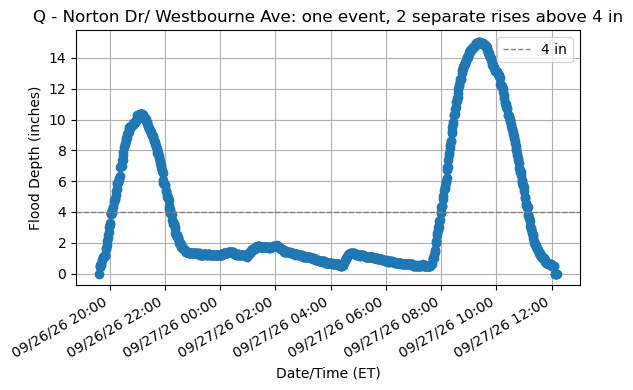

Event start:    2026-09-26 19:36 ET
Peak to peak:   12.3 h (tidal period 12.42 h)
Duration:       16.6 h
Time above 4 in: 5.2 h


In [10]:
example = (
    multi_df
    .with_columns(
        pl.col("peak_to_peak_h").list.eval((pl.element() - M2_HOURS).abs()).list.min()
        .alias("off_tidal_h")
    )
    .sort(["off_tidal_h", "flood_start_time"])
    .head(1)
)
row = example.row(0, named=True)

fig, ax = floodnet.plot_flood_event(example)
ax.axhline(FLOOD_IN, color="gray", linestyle="--", linewidth=1, label=f"{FLOOD_IN} in")
ax.legend(loc="upper right")
ax.set_title(f"{row['sensor_name']}: one event, {row['rises']} separate rises above {FLOOD_IN} in")
plt.tight_layout()
plt.show()

print(f"Event start:    {row['flood_start_time_et']:%Y-%m-%d %H:%M} ET")
print(f"Peak to peak:   {', '.join(f'{h:.1f} h' for h in row['peak_to_peak_h'])} "
      f"(tidal period {M2_HOURS} h)")
print(f"Duration:       {row['duration_mins'] / 60:.1f} h")
print(f"Time above {FLOOD_IN} in: {row['duration_above_4_inches_mins'] / 60:.1f} h")

Look for separate humps divided by a trough, and compare the printed peak-to-peak spacing with the tidal period: spacing close to 12.4 hours fits two high tides with the water not fully draining in between. Compare the event's duration with its time above 4 inches: per-event durations at tidal sensors partly measure how many tides merged.

**How to check a long tidal event.** A long `duration_mins` at a tidal sensor can mean several different things, and only the depth profile tells them apart:

- **Several tides merged**: separate humps about 12 or 24 hours apart.
- **One sustained rise**: a single long hump, for example a storm surge holding water high through a tide cycle.
- **Water that can't drain, or something under the sensor**: a long, flat, often shallow record. It may be real ponding, or an object or snow left under the sensor (caveat 2).

Plot the profile with `floodnet.plot_flood_event` before reading a long tidal event as one long flood.

# 3) Tides in the Timing

If tides cause the flooding, a sensor should flood on successive high tides: about **12.4 hours** apart, or **24.8 hours** apart when only one of the day's two high tides is high enough. For each sensor, we take the time from one event's start to the next event's start, and pool these gaps by sensor type. Rain floods have no such rhythm, so non-tidal sensors are the contrast.

This section uses all **events**, not just floods: a tide that wets the street without reaching 4 inches still marks the timing. The dashed lines mark multiples of 12.42 hours.

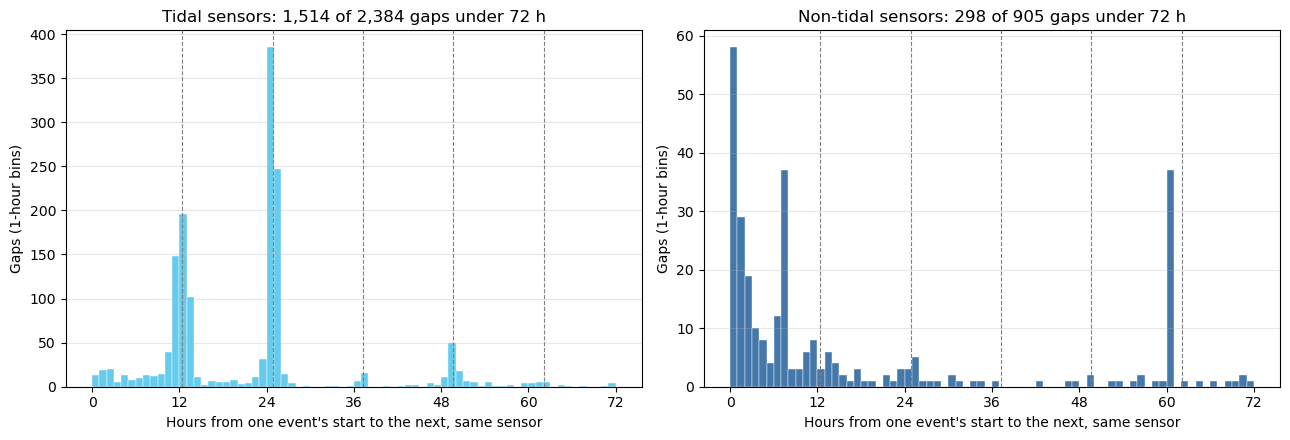

Tidal    : median gap   25.2 h, 63.5% of gaps under 72 h
Non-tidal: median gap  404.6 h, 32.9% of gaps under 72 h


In [11]:
MAX_GAP_H = 72  # display window: three days

gaps_df = (
    merged_df.sort("sensor_id", "flood_start_time")
    .with_columns(
        (pl.col("flood_start_time").diff().over("sensor_id").dt.total_seconds() / 3600)
        .alias("gap_h")
    )
    .filter(pl.col("gap_h").is_not_null())
)

bins = np.arange(0, MAX_GAP_H + 1, 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, flag, color, label in [
    (axes[0], "Yes", TIDAL_COLOR, "Tidal"),
    (axes[1], "No", NON_TIDAL_COLOR, "Non-tidal"),
]:
    gaps = gaps_df.filter(pl.col("tidally_influenced") == flag)["gap_h"]
    shown = gaps.filter(gaps < MAX_GAP_H)
    ax.hist(shown, bins=bins, color=color, edgecolor="white", linewidth=0.3)
    for k in range(1, int(MAX_GAP_H / M2_HOURS) + 1):
        ax.axvline(k * M2_HOURS, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(f"{label} sensors: {shown.len():,} of {gaps.len():,} gaps under {MAX_GAP_H} h")
    ax.set_xlabel("Hours from one event's start to the next, same sensor")
    ax.set_ylabel("Gaps (1-hour bins)")
    ax.set_xticks(np.arange(0, MAX_GAP_H + 1, 12))
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

for flag, label in [("Yes", "Tidal"), ("No", "Non-tidal")]:
    gaps = gaps_df.filter(pl.col("tidally_influenced") == flag)["gap_h"]
    print(f"{label:9s}: median gap {gaps.median():6.1f} h, "
          f"{(gaps < MAX_GAP_H).mean() * 100:4.1f}% of gaps under {MAX_GAP_H} h")

In the tidal panel, look for tall bars at the dashed lines. A peak at 24.8 hours that is taller than the one at 12.4 hours is consistent with New York's **unequal** twice-daily tides: one of the day's two high tides is usually higher, and often only that one floods the street. That is an interpretation, not something this data can confirm. The non-tidal panel shows what timing without a tidal rhythm looks like. A tall, narrow spike there usually means two storms that each flooded many sensors: every one of those sensors adds the same gap. It's a reminder that pooled gaps aren't independent, at tidal sensors as much as non-tidal ones.

Hour of day, which [05](https://github.com/mebauer/floodnet-nyc-tutorial/blob/main/05-temporal-patterns.ipynb) uses for rain-driven flooding, is the wrong axis here: high tide comes about 50 minutes later each day, so tidal floods spread across the whole clock.

## Per Sensor

As Section 1 showed, a few sensors record most tidal events, so the pooled panel mostly describes them. Below are the tidal sensors with the most events, one panel each.

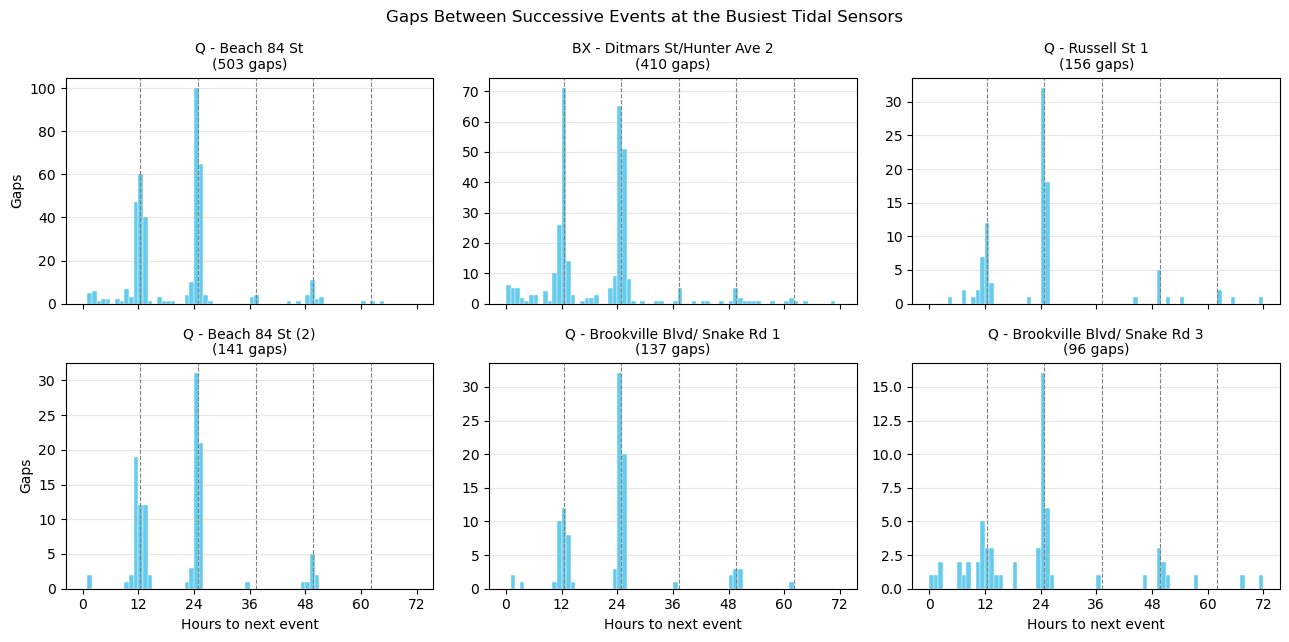

In [12]:
N_PANELS = 6  # display choice

busiest = (
    gaps_df.filter(pl.col("tidally_influenced") == "Yes")
    .group_by("sensor_id", "sensor_name")
    .agg(pl.len().alias("gaps"))
    .sort(["gaps", "sensor_id"], descending=[True, False])
    .head(N_PANELS)
)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for ax, s in zip(axes.flat, busiest.iter_rows(named=True)):
    gaps = gaps_df.filter(pl.col("sensor_id") == s["sensor_id"])["gap_h"]
    ax.hist(gaps.filter(gaps < MAX_GAP_H), bins=bins, color=TIDAL_COLOR,
            edgecolor="white", linewidth=0.3)
    for k in range(1, int(MAX_GAP_H / M2_HOURS) + 1):
        ax.axvline(k * M2_HOURS, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(f"{s['sensor_name']}\n({s['gaps']} gaps)", fontsize=10)
    ax.set_xticks(np.arange(0, MAX_GAP_H + 1, 12))
    ax.grid(axis="y", alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("Hours to next event")
for ax in axes[:, 0]:
    ax.set_ylabel("Gaps")
fig.suptitle("Gaps Between Successive Events at the Busiest Tidal Sensors")
plt.tight_layout()
plt.show()

Check whether each sensor shows the same peaks as the pooled chart. A sensor without them may flood mostly from rain, from storm surge lasting several tides, or only rarely; its flag says the site is tidally influenced, not that every event is a tide.

# 4) Spring and Neap Tides

Tides are highest around new and full moon (spring tides) and lowest in between (neap tides). If high tides drive the flooding, floods should cluster in the days after new or full moon.

For each flood we compute the **days since the most recent new or full moon**, which runs from 0 to about 14.8 days. We use the average length of the lunar month (29.53 days) counted from a known new moon. Real new and full moons drift up to about 14 hours from this average, which is small next to a two-week cycle. Moon phase belongs to an instant, so we compute it from the UTC start time, not the ET date.

Expect the peak a little **after** new or full moon, not exactly on it: the largest tides can arrive up to a day or two later (the "age of the tide").

In [13]:
SYNODIC_DAYS = 29.530588853  # mean lunar month (new moon to new moon)
HALF_CYCLE = SYNODIC_DAYS / 2  # new to full, or full to new
REF_NEW_MOON = datetime(2000, 1, 6, 18, 14, tzinfo=timezone.utc)  # Meeus, Astronomical Algorithms


def days_since_syzygy(ts):
    """Days since the most recent new or full moon, for a UTC datetime expression."""
    return ((ts - pl.lit(REF_NEW_MOON)).dt.total_seconds() / 86400) % HALF_CYCLE

**Count each day once.** A single high tide can flood many sensors at once, and the busiest sensors flood on most spring tides. Counting every flood would treat one tide as many separate observations. So we count **tidal flood days**: New York calendar dates on which at least one tidal sensor recorded a flood, with the moon phase taken at that day's first flood.

**What to compare against.** Days with an active tidal sensor are themselves spread over the lunar cycle. The gray line shows how flood days would be spread if flooding ignored the moon: the same total, distributed like all the days on which at least one tidal sensor was deployed.

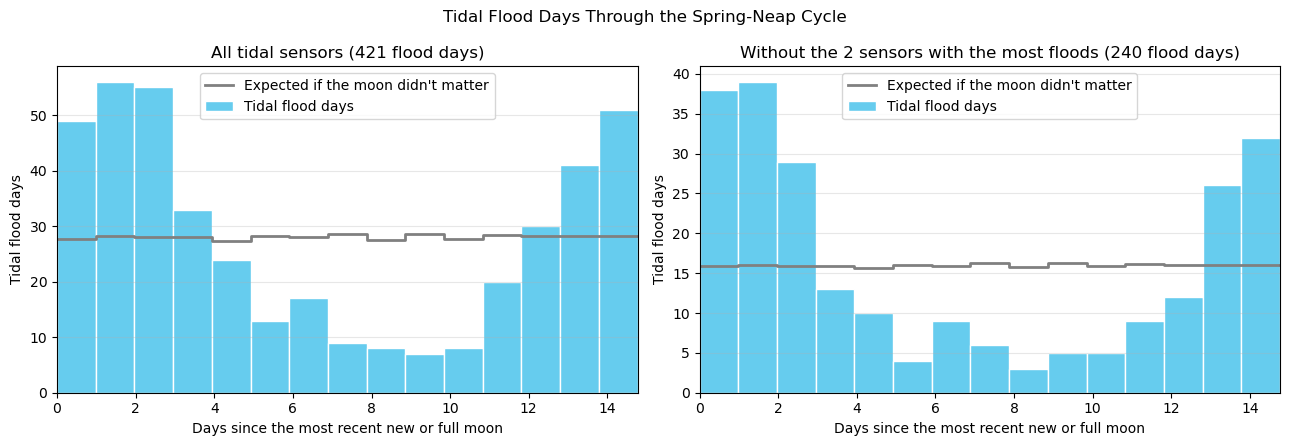

Tidal flood days: 421 (240 without the 2 sensors with the most floods)
Days with at least one tidal sensor deployed: 2,076


In [14]:
def flood_days(floods_df):
    """One row per ET date with a tidal flood, with the moon phase at its first flood."""
    return (
        floods_df
        .with_columns(pl.col("flood_start_time_et").dt.date().alias("date_et"))
        .group_by("date_et")
        .agg(pl.col("flood_start_time").min())
        .with_columns(days_since_syzygy(pl.col("flood_start_time")).alias("moon_days"))
    )


flood_days_df = flood_days(tidal_floods_df)
# the same, without the two sensors with the most floods (Section 1)
top2_ids = top_tidal["sensor_id"].head(2)
flood_days_without_top2_df = flood_days(
    tidal_floods_df.filter(~pl.col("sensor_id").is_in(top2_ids.implode()))
)

# every ET date on which at least one tidal sensor was deployed
tidal_meta = metadata_df.filter(pl.col("tidally_influenced") == "Yes").select(
    pl.col("date_installed").dt.date(), pl.col("date_removed").dt.date()
)
all_days = pl.date_range(tidal_meta["date_installed"].min(), data_cutoff, eager=True).alias("date_et")
active_days_df = (
    pl.DataFrame(all_days)
    .join(tidal_meta, how="cross")
    .filter(
        (pl.col("date_installed") <= pl.col("date_et"))
        & (pl.col("date_removed").is_null() | (pl.col("date_removed") >= pl.col("date_et")))
    )
    .select("date_et").unique()
    # moon phase at noon ET on each date
    .with_columns(
        pl.col("date_et").cast(pl.Datetime("us")).dt.offset_by("12h")
        .dt.replace_time_zone(floodnet.NYC_TZ).dt.convert_time_zone("UTC").alias("noon")
    )
    .with_columns(days_since_syzygy(pl.col("noon")).alias("moon_days"))
)

N_BINS = 15  # about one day per bin
edges = np.linspace(0, HALF_CYCLE, N_BINS + 1)
reference, _ = np.histogram(active_days_df["moon_days"], bins=edges)
centers = (edges[:-1] + edges[1:]) / 2

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, days_df, title in [
    (axes[0], flood_days_df, "All tidal sensors"),
    (axes[1], flood_days_without_top2_df, "Without the 2 sensors with the most floods"),
]:
    observed, _ = np.histogram(days_df["moon_days"], bins=edges)
    expected = reference / reference.sum() * observed.sum()
    ax.bar(centers, observed, width=edges[1] - edges[0], color=TIDAL_COLOR,
           edgecolor="white", label="Tidal flood days")
    ax.step(edges, np.append(expected, expected[-1]), where="post", color="gray",
            linewidth=2, label="Expected if the moon didn't matter")
    ax.set_xlabel("Days since the most recent new or full moon")
    ax.set_ylabel("Tidal flood days")
    ax.set_title(f"{title} ({days_df.height:,} flood days)")
    ax.set_xlim(0, HALF_CYCLE)
    ax.legend(loc="upper center")
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("Tidal Flood Days Through the Spring-Neap Cycle")
plt.tight_layout()
plt.show()

print(f"Tidal flood days: {flood_days_df.height:,} "
      f"({flood_days_without_top2_df.height:,} without the 2 sensors with the most floods)")
print(f"Days with at least one tidal sensor deployed: {active_days_df.height:,}")

The cycle wraps around: day 14.8 is the next new or full moon, so the left and right edges of the chart are neighbors. Spring tides sit at both edges, neap tides in the middle. Compare the bars with the gray line: bars above it near the edges and below it in the middle mean more flood days around spring tides.

Then look at where the tallest bars sit. Spring tides would put them within the first day or two after new or full moon, at the left edge; the phase itself is only accurate to within about 14 hours, so don't read the exact day too closely.

Compare the two panels. The flood-day counts in their titles show how much of the left panel comes from the two busiest sensors. If the right panel shows the same shape, the spring-tide pattern isn't just those two sensors.

**Keep in mind:** spring tides last several days, so neighboring flood days aren't independent observations. The chart shows whether flooding follows the lunar cycle, not a precise measure of how strongly.

# 5) Seasonality

Does tidal flooding change through the year? We count floods (peak ≥ 4 in) per 100 **active sensor-months**, as in [05](https://github.com/mebauer/floodnet-nyc-tutorial/blob/main/05-temporal-patterns.ipynb): a tidal sensor counts as active in a month if it was installed on or before the month's last day and not removed before its first. Months come from the ET dates. The latest month is left out because it is incomplete (caveat 8).

We pool each calendar month across all years, then show the number of sensor-months behind each rate. Because a few sensors record most floods (Section 1), the chart also shows the rate without the two sensors with the most floods. Two sensors aren't necessarily two sites: another sensor at the same street, such as one whose name differs only by a suffix like "(2)", stays in that line (caveat 9). Check the Section 1 table for those.

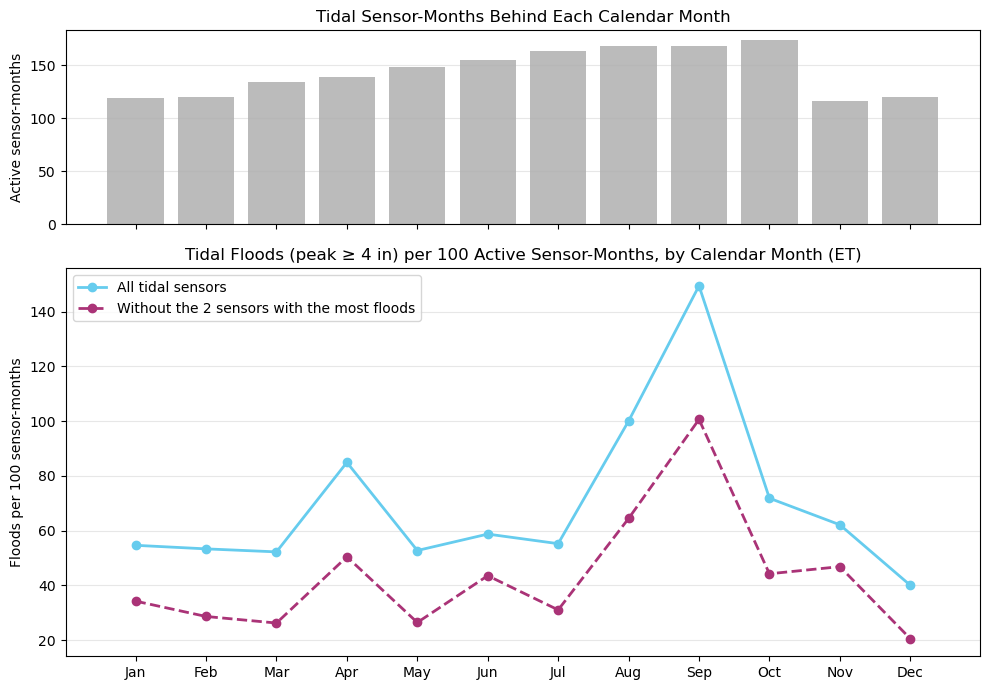

Window: 2021-03-01 to 2026-10-01 (68 months, ET)


month,sensor_months,floods,floods_per_100_sensor_months,without_top2
str,u32,u32,f64,f64
"""Jan""",119,65,54.6,34.2
"""Feb""",120,64,53.3,28.6
"""Mar""",134,70,52.2,26.2
"""Apr""",139,118,84.9,50.4
"""May""",148,78,52.7,26.4
"""Jun""",155,91,58.7,43.5
"""Jul""",163,90,55.2,31.0
"""Aug""",168,168,100.0,64.4
"""Sep""",168,251,149.4,100.6


In [15]:
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

floods_m = tidal_floods_df.with_columns(
    pl.col("flood_start_time_et").dt.date().dt.truncate("1mo").alias("month_start")
)
window_end = data_cutoff.replace(day=1)  # first day of the latest (partial) month

tidal_sensors = metadata_df.filter(pl.col("tidally_influenced") == "Yes").select(
    "sensor_id", pl.col("date_installed").dt.date(), pl.col("date_removed").dt.date()
)
months = pl.date_range(
    tidal_sensors["date_installed"].min().replace(day=1), window_end,
    interval="1mo", closed="left", eager=True,
).alias("month_start")

sensor_months_df = (
    tidal_sensors.join(pl.DataFrame(months), how="cross")
    .with_columns(pl.col("month_start").dt.month_end().alias("month_end"))
    .filter(
        (pl.col("date_installed") <= pl.col("month_end"))
        & (pl.col("date_removed").is_null() | (pl.col("date_removed") >= pl.col("month_start")))
    )
)

def monthly_rate(exclude=None):
    sm = sensor_months_df
    fl = floods_m.filter(pl.col("month_start") < window_end)
    if exclude is not None:
        sm = sm.filter(~pl.col("sensor_id").is_in(exclude.implode()))
        fl = fl.filter(~pl.col("sensor_id").is_in(exclude.implode()))
    return (
        pl.DataFrame({"month": range(1, 13)})
        .join(sm.group_by(pl.col("month_start").dt.month().alias("month"))
              .agg(pl.len().alias("sensor_months")), on="month", how="left")
        .join(fl.group_by(pl.col("month_start").dt.month().alias("month"))
              .agg(pl.len().alias("floods")), on="month", how="left")
        .fill_null(0)
        .with_columns((pl.col("floods") / pl.col("sensor_months") * 100).round(1)
                      .alias("floods_per_100_sensor_months"))
    )


all_rate = monthly_rate()
without_top2 = monthly_rate(exclude=top2_ids)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                         gridspec_kw={"height_ratios": [1, 2]})
axes[0].bar(all_rate["month"], all_rate["sensor_months"], color=colors[6])
axes[0].set_ylabel("Active sensor-months")
axes[0].set_title("Tidal Sensor-Months Behind Each Calendar Month")
axes[1].plot(all_rate["month"], all_rate["floods_per_100_sensor_months"],
             marker="o", color=TIDAL_COLOR, linewidth=2, label="All tidal sensors")
axes[1].plot(without_top2["month"], without_top2["floods_per_100_sensor_months"],
             marker="o", color=colors[5], linewidth=2, linestyle="--",
             label="Without the 2 sensors with the most floods")
axes[1].set_ylabel("Floods per 100 sensor-months")
axes[1].set_title(f"Tidal Floods (peak ≥ {FLOOD_IN} in) per 100 Active Sensor-Months, by Calendar Month (ET)")
axes[1].set_xticks(range(1, 13), month_labels)
axes[1].legend()
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Window: {months.min()} to {months.max()} ({len(months)} months, ET)")
with pl.Config(tbl_rows=12):
    display(
        all_rate.join(
            without_top2.select("month", pl.col("floods_per_100_sensor_months").alias("without_top2")),
            on="month",
        ).with_columns(pl.col("month").replace_strict(range(1, 13), month_labels, return_dtype=pl.Utf8))
    )

How to read this:

- **Check the top panel first.** Months with fewer sensor-months rest on less data. Because the network grew over time, every calendar-month rate is weighted toward the most recent years, when most tidal sensors were deployed.
- **Compare the two lines.** If they rise and fall together, the seasonal pattern isn't just the two busiest sensors. If they diverge, the pooled line mostly describes those two sensors.
- **Winter months need extra care.** Snow piled under a sensor can produce false readings or hide a shallow flood (caveat 2).
- **Seasonal tides and storms aren't separated in this data.** A month can stand out because tides run higher then, because coastal storms (nor'easters, tropical storms) push water in, or because of a single storm that happened to land in that month. Without a tide record, we can't tell which.

# 6) Limitations

**What this notebook shows you how to check**

- How the tidal and non-tidal groups compare in size, exposure and flooding, and how much a pooled tidal result depends on a few sensors (Section 1).
- How to spot an event that spans more than one tide, and why long tidal events need their depth profile checked (Section 2).
- Whether flood timing at tidal sensors follows the 12.4-hour tide, pooled and per sensor (Section 3), and the spring-neap cycle (Section 4).
- How tidal flooding varies by calendar month, normalized by the sensors deployed (Section 5).

**What this data can't tell us**

- *No tide or water-level record.* The timing patterns are consistent with tides, not confirmation of them. Comparing floods with a tide gauge (NOAA stations such as The Battery, Kings Point or Sandy Hook, or USGS gauges in Jamaica Bay) would show which high tides flooded, and observed minus predicted water level would separate storm surge from the ordinary tide.
- *Other tidal cycles.* The moon's distance also changes, on a cycle of about 27.6 days. Spring tides near its closest point (perigee) are the highest of the year, sometimes called king tides. That cycle is mixed into Section 4.
- *Rain at tidal sensors.* The tidal flag is per sensor, not per event, so rain-driven floods at tidal sensors are included in Sections 3–5 and blur the timing patterns.
- *Not a ranking of where tidal flooding is worst.* Counts and rates are observed at each sensor and depend on where it was mounted (caveat 1), how long it has been deployed, and how the site was chosen (caveat 5). Sensors with no events may have been offline (caveat 6).
- *Per sensor, not per site.* A replaced sensor gets a new id, and its tidal flag can differ (Section 1, caveat 9).

See [METHODS.md](METHODS.md) for the full list of caveats and the definitions used here.